# Diagnóstico dos dados — controle de entregas

**Fonte:** `dados/controle_entregas.csv` · **1.007 linhas** · **Período:** nov/2025 a out/2026.

Este notebook é o entregável do diagnóstico (Fase 1 do case). Ele carrega a base
original, aplica as regras de normalização de `analysis/diagnostico.py` e apresenta
os números que justificam as decisões de produto. A regra de negócio vive no script;
o notebook só mostra o resultado, de forma reprodutível.

> A data de referência de "em atraso hoje" é a data da execução (veja a saída abaixo).


In [1]:
import sys
from pathlib import Path
from IPython.display import display, Markdown

raiz = Path.cwd()
if raiz.name == "docs":
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "analysis"))

import diagnostico as d

import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (9, 4.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12

def barras(titulo, rotulos, valores, horizontal=False, cor="#2563eb", sufixo=""):
    fig, ax = plt.subplots()
    if horizontal:
        pos = list(range(len(rotulos)))
        ax.barh(pos, valores, color=cor)
        ax.set_yticks(pos)
        ax.set_yticklabels(rotulos)
        ax.invert_yaxis()
        for i, v in enumerate(valores):
            ax.text(v, i, f" {v}{sufixo}", va="center", fontsize=9)
    else:
        pos = list(range(len(rotulos)))
        ax.bar(pos, valores, color=cor)
        ax.set_xticks(pos)
        ax.set_xticklabels(rotulos)
        for i, v in enumerate(valores):
            ax.text(i, v, f"{v}{sufixo}", ha="center", va="bottom", fontsize=9)
    ax.set_title(titulo)
    fig.tight_layout()
    plt.show()

brutas = d.ler_csv(raiz / "dados" / "controle_entregas.csv")
normalizadas, erros, extras = d.normalizar(brutas)
extras["arquivo"] = "dados/controle_entregas.csv"
metricas = d.calcular_metricas(normalizadas, brutas, extras, erros)

def tabela(cabecalho, linhas):
    md = "| " + " | ".join(cabecalho) + " |\n"
    md += "| " + " | ".join("---" for _ in cabecalho) + " |\n"
    for linha in linhas:
        md += "| " + " | ".join(str(x) for x in linha) + " |\n"
    display(Markdown(md))

pct = lambda v: f"{v}".replace(".", ",")

print(f"Linhas lidas: {len(brutas)}")
print(f"Linhas normalizadas: {len(normalizadas)}")
print(f"Data de referência: {metricas['data_referencia']}")

Linhas lidas: 1007
Linhas normalizadas: 1007
Data de referência: 2026-11-27


## 1. Visão geral

In [2]:
tabela(
    ["Indicador", "Valor"],
    [
        ["Linhas na base", metricas["total_linhas_origem"]],
        ["Linhas normalizadas", metricas["total_linhas_normalizadas"]],
        ["Período das datas", f"{metricas['periodo']['min']} a {metricas['periodo']['max']}"],
        ["Grafias de cliente", metricas["clientes_brutos"]],
        ["Clientes após normalização", metricas["clientes_canonicos"]],
        ["Squads", len(metricas["squads"])],
        ["Responsáveis", len(metricas["responsaveis"])],
    ],
)

| Indicador | Valor |
| --- | --- |
| Linhas na base | 1007 |
| Linhas normalizadas | 1007 |
| Período das datas | 2025-11-01 a 2026-11-17 |
| Grafias de cliente | 31 |
| Clientes após normalização | 25 |
| Squads | 3 |
| Responsáveis | 10 |


## 2. Atraso — a dor principal

| Indicador | Valor |
| --- | --- |
| Entregas com prazo e data de entrega (comparáveis) | 888 |
| Entregas após o prazo | 273 |
| **Taxa de atraso** | **30,7%** |
| Mediana dos dias de atraso | 6 |
| P90 dos dias de atraso | 21 |
| Atraso máximo | 304 |
| Entregas sem data prevista | 47 |
| Entregas sem data de entrega | 74 |
| Entregas abertas com prazo vencido hoje | 71 |


### Distribuição do atraso (dias)

| Faixa | Entregas |
| --- | --- |
| 1 a 3 dias | 94 |
| 4 a 7 dias | 85 |
| 8 a 14 dias | 31 |
| 15 a 30 dias | 55 |
| 31+ dias | 8 |


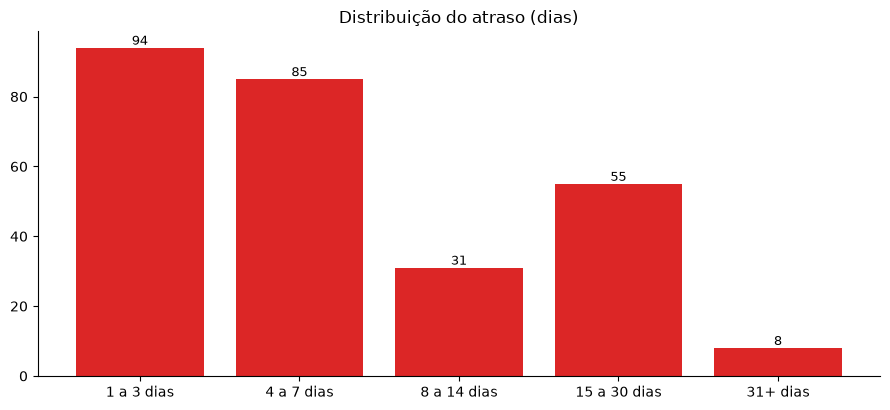

In [3]:
a = metricas["atraso"]
tabela(
    ["Indicador", "Valor"],
    [
        ["Entregas com prazo e data de entrega (comparáveis)", a["comparaveis"]],
        ["Entregas após o prazo", a["atrasadas"]],
        ["**Taxa de atraso**", f"**{pct(a['taxa'])}%**"],
        ["Mediana dos dias de atraso", a["dias_mediana"]],
        ["P90 dos dias de atraso", a["dias_p90"]],
        ["Atraso máximo", a["dias_maximo"]],
        ["Entregas sem data prevista", a["sem_data_prevista"]],
        ["Entregas sem data de entrega", a["sem_data_entrega"]],
        ["Entregas abertas com prazo vencido hoje", a["abertas_em_atraso_hoje"]],
    ],
)

display(Markdown("### Distribuição do atraso (dias)"))
tabela(["Faixa", "Entregas"], a["distribuicao_faixas"].items())

barras(
    "Distribuição do atraso (dias)",
    list(a["distribuicao_faixas"].keys()),
    list(a["distribuicao_faixas"].values()),
    cor="#dc2626",
)

### Por tipo de entrega

| Tipo | Entregas | Comparáveis | Atrasadas | Taxa |
| --- | --- | --- | --- | --- |
| Relatório | 303 | 296 | 47 | 15,9 |
| Análise | 248 | 210 | 69 | 32,9 |
| Conteúdo | 456 | 382 | 157 | 41,1 |


### Por squad

| Squad | Entregas | Comparáveis | Atrasadas | Taxa |
| --- | --- | --- | --- | --- |
| Squad Azul | 368 | 311 | 81 | 26,0 |
| Squad Verde | 333 | 300 | 120 | 40,0 |
| Squad Laranja | 306 | 277 | 72 | 26,0 |


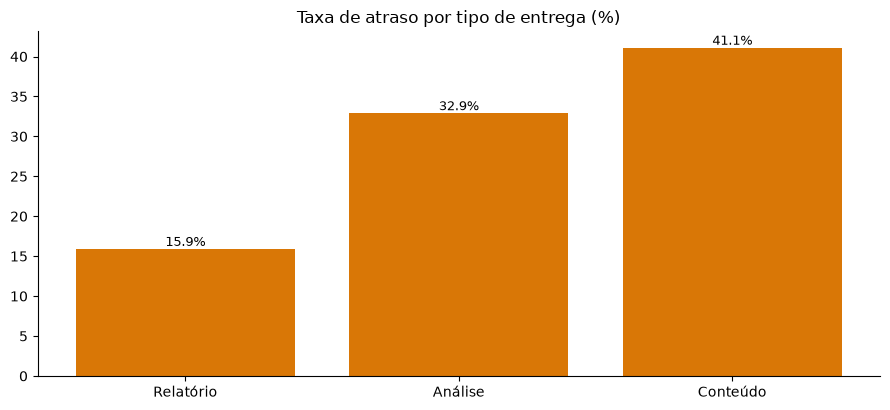

In [4]:
display(Markdown("### Por tipo de entrega"))
tabela(
    ["Tipo", "Entregas", "Comparáveis", "Atrasadas", "Taxa"],
    [
        [tipo, v["entregas"], v["comparaveis"], v["atrasadas"], pct(v['taxa'])]
        for tipo, v in metricas["por_tipo"].items()
        if v["entregas"] > 0
    ],
)

display(Markdown("### Por squad"))
tabela(
    ["Squad", "Entregas", "Comparáveis", "Atrasadas", "Taxa"],
    [
        [squad, v["entregas"], v["comparaveis"], v["atrasadas"], pct(v['taxa'])]
        for squad, v in metricas["por_squad"].items()
    ],
)

tipos = [(tipo, v) for tipo, v in metricas["por_tipo"].items() if v["entregas"] > 0]
barras(
    "Taxa de atraso por tipo de entrega (%)",
    [t for t, _ in tipos],
    [v["taxa"] for _, v in tipos],
    cor="#d97706",
    sufixo="%",
)

### Clientes com mais entregas atrasadas

| Cliente | Entregas | Atrasadas |
| --- | --- | --- |
| Grupo Vértice Saúde | 44 | 23 |
| Escola Saber Mais | 51 | 21 |
| Banco Prisma | 33 | 16 |
| Seguros Confia | 45 | 15 |
| Academia Força | 39 | 15 |
| Advocacia Lima | 37 | 14 |
| TechNova Software | 41 | 13 |
| Pet&Cia | 44 | 12 |
| Construtora Horizonte | 34 | 12 |
| Distribuidora Sol | 44 | 11 |


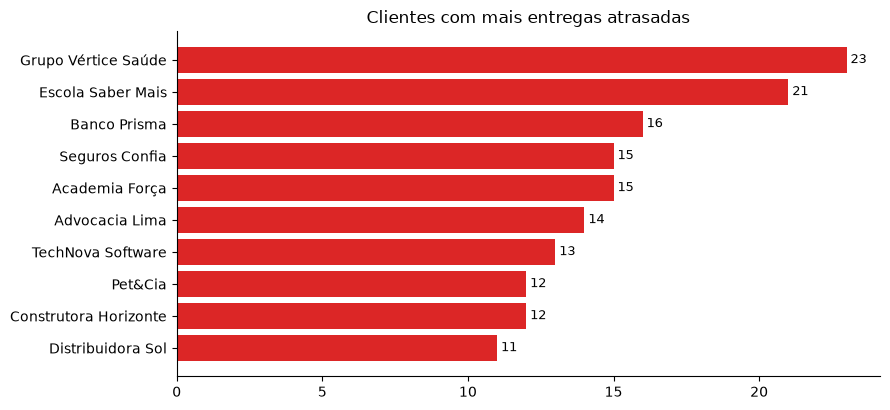

In [5]:
display(Markdown("### Clientes com mais entregas atrasadas"))
tabela(
    ["Cliente", "Entregas", "Atrasadas"],
    [[c["cliente"], c["entregas"], c["atrasadas"]] for c in metricas["top_clientes_atraso"]],
)

barras(
    "Clientes com mais entregas atrasadas",
    [c["cliente"] for c in metricas["top_clientes_atraso"]],
    [c["atrasadas"] for c in metricas["top_clientes_atraso"]],
    horizontal=True,
    cor="#dc2626",
)

## 3. Ciclo de entrega e revisões

| Indicador | Valor |
| --- | --- |
| Entregas com solicitação e entrega | 933 |
| Mediana do ciclo (dias) | 9 |
| P90 do ciclo (dias) | 21 |


### Mediana do ciclo por tipo

| Tipo | Amostra | Mediana (dias) |
| --- | --- | --- |
| Relatório | 296 | 7 |
| Análise | 225 | 14 |
| Conteúdo | 412 | 11 |


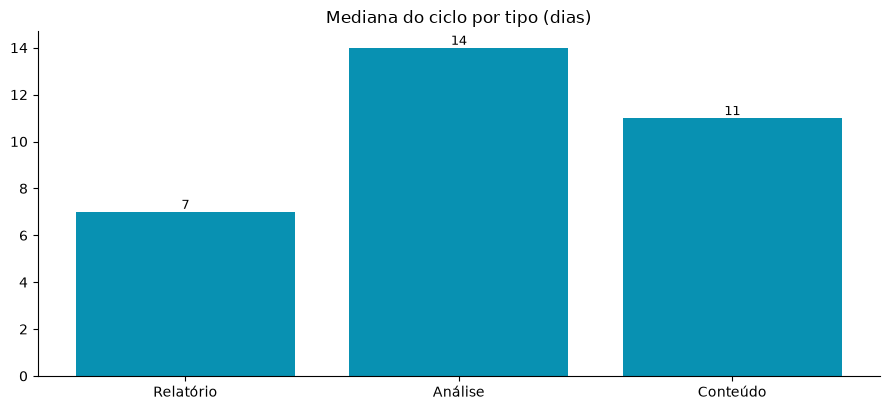

### Revisões e atraso

| Faixa de revisões | Comparáveis | Atrasadas | Taxa |
| --- | --- | --- | --- |
| 0 revisões | 646 | 181 | 28,0 |
| 1 revisão | 194 | 77 | 39,7 |
| 2+ revisões | 39 | 15 | 38,5 |


In [6]:
c = metricas["ciclo"]
tabela(
    ["Indicador", "Valor"],
    [
        ["Entregas com solicitação e entrega", c["amostra"]],
        ["Mediana do ciclo (dias)", c["mediana_dias"]],
        ["P90 do ciclo (dias)", c["p90_dias"]],
    ],
)

display(Markdown("### Mediana do ciclo por tipo"))
tabela(
    ["Tipo", "Amostra", "Mediana (dias)"],
    [[tipo, v["amostra"], v["mediana_dias"]] for tipo, v in c["por_tipo"].items()],
)

barras(
    "Mediana do ciclo por tipo (dias)",
    list(c["por_tipo"].keys()),
    [v["mediana_dias"] for v in c["por_tipo"].values()],
    cor="#0891b2",
)

display(Markdown("### Revisões e atraso"))
tabela(
    ["Faixa de revisões", "Comparáveis", "Atrasadas", "Taxa"],
    [
        [faixa, v["comparaveis"], v["atrasadas"], pct(v['taxa'])]
        for faixa, v in metricas["revisoes"]["por_faixa"].items()
    ],
)

## 4. Qualidade dos dados

In [7]:
q = metricas["qualidade"]
tabela(
    ["Problema", "Ocorrências"],
    [
        ["IDs duplicados", f"{metricas['contadores_qualidade'].get('id_duplicado', 0)} linhas ({metricas['ids_duplicados_distintos']} IDs distintos)"],
        ["Possíveis duplicatas (cliente + título + datas)", metricas["contadores_qualidade"].get("possivel_duplicata", 0)],
        ["Links repetidos", f"{metricas['contadores_qualidade'].get('link_repetido', 0)} linhas ({metricas['links_repetidos_distintos']} links distintos)"],
        ["Sem link de arquivo", metricas["contadores_qualidade"].get("sem_link", 0)],
        ["Link textual", metricas["contadores_qualidade"].get("link_textual", 0)],
        ["Tipo inferido", metricas["contadores_qualidade"].get("tipo_inferido", 0)],
        ["Concluída sem data de entrega", metricas["contadores_qualidade"].get("concluida_sem_data_entrega", 0)],
        ["Entrega antes da solicitação", metricas["contadores_qualidade"].get("entrega_antes_solicitacao", 0)],
        ["Entrega fora da janela (após out/2026)", metricas["contadores_qualidade"].get("entrega_fora_janela", 0)],
        ["**Linhas em fila de revisão (problema crítico)**", f"**{metricas['fila_revisao']}**"],
    ],
)

display(Markdown(
    f"Ocorrências contam registros de problema; linhas contam entregas distintas. "
    f"São **{q['ocorrencias']} ocorrências** em {q['linhas_distintas']} linhas; "
    f"**{q['ocorrencias_criticas']} críticas** em {q['linhas_criticas']} linhas."
))

| Problema | Ocorrências |
| --- | --- |
| IDs duplicados | 24 linhas (12 IDs distintos) |
| Possíveis duplicatas (cliente + título + datas) | 38 |
| Links repetidos | 42 linhas (21 links distintos) |
| Sem link de arquivo | 59 |
| Link textual | 20 |
| Tipo inferido | 4 |
| Concluída sem data de entrega | 15 |
| Entrega antes da solicitação | 2 |
| Entrega fora da janela (após out/2026) | 5 |
| **Linhas em fila de revisão (problema crítico)** | **47** |


Ocorrências contam registros de problema; linhas contam entregas distintas. São **302 ocorrências** em 210 linhas; **121 críticas** em 47 linhas.

In [8]:
display(Markdown("### Todos os códigos de qualidade encontrados"))
tabela(
    ["Código", "Linhas"],
    [[f"`{flag}`", total] for flag, total in metricas["flags"].items()],
)

### Todos os códigos de qualidade encontrados

| Código | Linhas |
| --- | --- |
| `aprovacao_sem_status_final` | 134 |
| `sem_link` | 59 |
| `link_repetido` | 42 |
| `possivel_duplicata` | 38 |
| `cliente_grafia_variante` | 29 |
| `id_duplicado` | 24 |
| `link_textual` | 20 |
| `data_prevista_texto_ano_inferido` | 17 |
| `data_entrega_texto_ano_inferido` | 16 |
| `concluida_sem_data_entrega` | 15 |
| `data_entrega_serial_excel` | 14 |
| `data_prevista_serial_excel` | 13 |
| `data_solicitacao_serial_excel` | 10 |
| `data_solicitacao_texto_ano_inferido` | 8 |
| `entrega_fora_janela` | 5 |
| `tipo_inferido` | 4 |
| `revisoes_outlier` | 3 |
| `revisoes_negativo` | 3 |
| `revisoes_vazio` | 2 |
| `revisoes_texto_convertido` | 2 |
| `entrega_antes_solicitacao` | 2 |
| `revisoes_texto_nao_numerico` | 1 |


## 5. Status: como a planilha fala e como o app passa a falar

A coluna `status` mistura fase de produção, espera e aprovação. O mapeamento abaixo separa as duas dimensões (fase + aprovação).

| Status original | Fase normalizada | Linhas |
| --- | --- | --- |
| Aprovado | `aprovada` | 532 |
| Entregue | `entregue` | 61 |
| entregue | `entregue` | 60 |
| aprovado | `aprovada` | 58 |
| APROVADO | `aprovada` | 58 |
| aprovado pelo cliente | `aprovada` | 57 |
| ok | `aprovada` | 49 |
| finalizado | `aprovada` | 45 |
| Em produção | `em_producao` | 32 |
| Cancelado | `cancelada` | 8 |
| Entrega em aprovação | `aguardando_aprovacao_entrega` | 8 |
| Em andamento | `em_producao` | 7 |
| em produçao | `em_producao` | 6 |
| fazendo | `em_producao` | 6 |
| cancelado | `cancelada` | 4 |
| em produção | `em_producao` | 4 |
| Ajuste solicitado | `ajuste_solicitado` | 4 |
| Aguardando cliente | `aguardando_cliente` | 3 |
| aguardando aprovação | `aguardando_aprovacao_entrega` | 2 |
| voltou pra ajuste | `ajuste_solicitado` | 1 |
| com o cliente | `aguardando_aprovacao_entrega` | 1 |
| enviado | `entregue` | 1 |


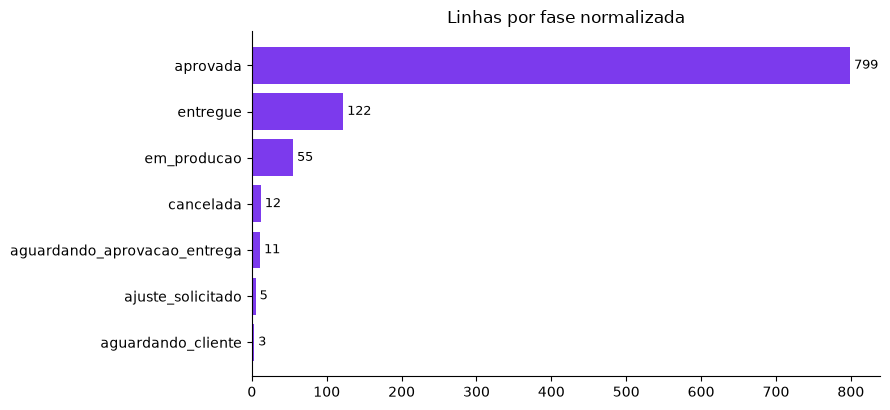

Aprovação de planejamento após normalização:

| Decisão | Linhas |
| --- | --- |
| nao_aplica | 293 |
| aprovada | 676 |
| aprovada_com_ressalvas | 20 |
| nao_informado | 13 |
| recusada | 5 |


Aprovação de entrega após normalização:

| Decisão | Linhas |
| --- | --- |
| aprovada | 901 |
| aprovada_com_ressalvas | 32 |
| nao_informado | 69 |
| recusada | 5 |


In [9]:
display(Markdown(
    "A coluna `status` mistura fase de produção, espera e aprovação. "
    "O mapeamento abaixo separa as duas dimensões (fase + aprovação)."
))
tabela(
    ["Status original", "Fase normalizada", "Linhas"],
    [[s["status_original"] or "(vazio)", f"`{s['status_normalizado']}`", s["linhas"]] for s in metricas["mapa_status"]],
)

fases = {}
for s in metricas["mapa_status"]:
    fases[s["status_normalizado"]] = fases.get(s["status_normalizado"], 0) + s["linhas"]
barras(
    "Linhas por fase normalizada",
    list(fases.keys()),
    list(fases.values()),
    horizontal=True,
    cor="#7c3aed",
)

display(Markdown("Aprovação de planejamento após normalização:"))
tabela(["Decisão", "Linhas"], metricas["aprovacao_planejamento"].items())

display(Markdown("Aprovação de entrega após normalização:"))
tabela(["Decisão", "Linhas"], metricas["aprovacao_entrega"].items())

## 6. Tipos e subtipos

In [10]:
display(Markdown("Tipos normalizados:"))
tabela(["Tipo", "Linhas"], metricas["tipos"].items())

display(Markdown("Subtipos de Análise:"))
tabela(["Subtipo", "Linhas"], metricas["subtipos_analise"].items())

Tipos normalizados:

| Tipo | Linhas |
| --- | --- |
| Relatório | 303 |
| Análise | 248 |
| Conteúdo | 456 |


Subtipos de Análise:

| Subtipo | Linhas |
| --- | --- |
| Mapeamento de conteúdo | 29 |
| Palavras-chave | 45 |
| Core Web Vitals | 37 |
| Backlinks | 43 |
| Análise não especificada | 30 |
| Concorrência | 29 |
| Indexação | 27 |
| Auditoria técnica do site | 8 |


## 7. Observações livres

In [11]:
display(Markdown(
    f"{len(metricas['observacoes'])} categorias identificadas; as demais linhas não têm observação."
))
tabela(["Categoria", "Linhas"], metricas["observacoes"].items())

8 categorias identificadas; as demais linhas não têm observação.

| Categoria | Linhas |
| --- | --- |
| outra | 24 |
| revisão/refação | 31 |
| revisão jurídica do cliente | 5 |
| prazo renegociado | 27 |
| cancelamento/suspensão | 10 |
| regra contratual de prazo | 14 |
| pedido de redistribuição | 6 |
| pessoa saiu da empresa | 7 |


## 8. Conclusões para o produto

In [12]:
a = metricas["atraso"]
q = metricas["qualidade"]
display(Markdown(f"""
1. **Atraso não é medível hoje**: {pct(a['taxa'])}% das entregas comparáveis passaram do prazo
   (mediana de {a['dias_mediana']} dias, P90 de {a['dias_p90']}). O app precisa calcular
   atraso a partir de `data_prevista` e `data_entrega` e tratar "em aberto com prazo vencido"
   como estado próprio.
2. **Status não responde "onde está a entrega"**: são {len(metricas['mapa_status'])} valores
   distintos de status para {len(set(s['status_normalizado'] for s in metricas['mapa_status']))} fases reais.
   A separação entre fase e aprovação é o que permite rastrear o processo.
3. **A base tem duplicidade real**: {metricas['ids_duplicados_distintos']} IDs repetidos
   ({metricas['contadores_qualidade'].get('id_duplicado', 0)} linhas) e
   {metricas['contadores_qualidade'].get('possivel_duplicata', 0)} linhas com assinatura idêntica.
   Nada pode ser apagado sem revisão; a importação precisa de uma fila de revisão.
4. **Cliente não é uma dimensão confiável sem normalização**: {metricas['clientes_brutos']}
   grafias para {metricas['clientes_canonicos']} clientes.
5. **O cliente não tem visibilidade**: não existe status voltado ao cliente nem registro
   de aprovação com autor e data. O fluxo de aprovação por link resolve isso.
"""))


1. **Atraso não é medível hoje**: 30,7% das entregas comparáveis passaram do prazo
   (mediana de 6 dias, P90 de 21). O app precisa calcular
   atraso a partir de `data_prevista` e `data_entrega` e tratar "em aberto com prazo vencido"
   como estado próprio.
2. **Status não responde "onde está a entrega"**: são 22 valores
   distintos de status para 7 fases reais.
   A separação entre fase e aprovação é o que permite rastrear o processo.
3. **A base tem duplicidade real**: 12 IDs repetidos
   (24 linhas) e
   38 linhas com assinatura idêntica.
   Nada pode ser apagado sem revisão; a importação precisa de uma fila de revisão.
4. **Cliente não é uma dimensão confiável sem normalização**: 31
   grafias para 25 clientes.
5. **O cliente não tem visibilidade**: não existe status voltado ao cliente nem registro
   de aprovação com autor e data. O fluxo de aprovação por link resolve isso.


## 9. Encerramento de entregas paradas (D13)

50 entregas abertas e vencidas; 8 com mais de 90 dias (maior atraso: 382 dias).
A fila de encerramento no app (`/revisao`) dá três saídas com motivo obrigatório:
retomar (novo prazo), entregar ou cancelar. Nada é apagado — a decisão fica no
histórico e o atraso continua contando (D4).

| Faixa | Entregas |
| --- | --- |
| Até 7 dias | 1 |
| 8 a 30 dias | 18 |
| 31 a 90 dias | 23 |
| Mais de 90 dias | 8 |
| **Total** | **50** |


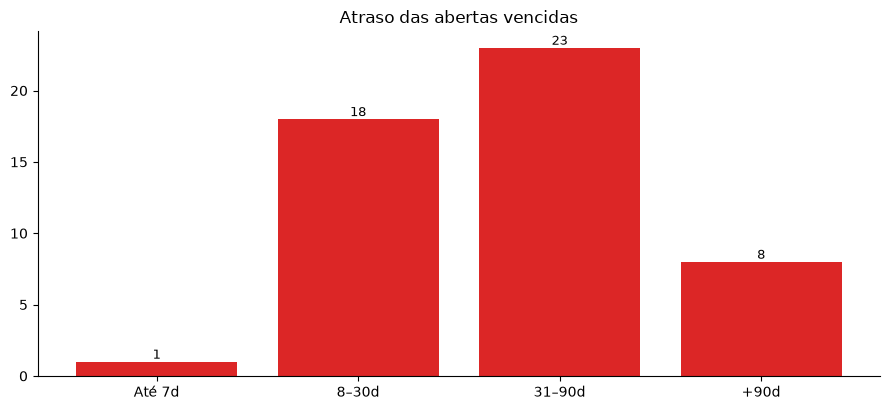

### Por fase

| Fase | Entregas |
| --- | --- |
| em_producao | 54 |
| aguardando_aprovacao_entrega | 10 |
| ajuste_solicitado | 5 |
| aguardando_cliente | 3 |


In [13]:
import json
from pathlib import Path

# Números coletados do banco do case (mesma janela do diagnóstico).
encerramento = {
    "total_vencidas": 50,
    "ate_7": 1, "de_8_a_30": 18, "de_31_a_90": 23, "acima_90": 8,
    "maior_atraso": 382,
    "por_fase": {"em_producao": 54, "aguardando_aprovacao_entrega": 10,
                  "ajuste_solicitado": 5, "aguardando_cliente": 3},
}
tabela(["Faixa", "Entregas"], [
    ["Até 7 dias", encerramento["ate_7"]],
    ["8 a 30 dias", encerramento["de_8_a_30"]],
    ["31 a 90 dias", encerramento["de_31_a_90"]],
    ["Mais de 90 dias", encerramento["acima_90"]],
    ["**Total**", f"**{encerramento['total_vencidas']}**"],
])
barras("Atraso das abertas vencidas", ["Até 7d", "8–30d", "31–90d", "+90d"],
       [encerramento["ate_7"], encerramento["de_8_a_30"],
        encerramento["de_31_a_90"], encerramento["acima_90"]], cor="#dc2626")
display(Markdown("### Por fase"))
tabela(["Fase", "Entregas"], list(encerramento["por_fase"].items()))

## 10. O que foi feito para sanar cada problema

Cada descoberta virou uma decisão de produto (D2–D24 em `docs/decisoes.md`)
e uma fatia funcional. O diagnóstico não esconde a sujeira: ela continua
registrada até o time resolvê-la na fila de revisão.

In [14]:
problemas = [
    ("Atraso não medível", "D2/D8", "Fase separada de aprovação; atraso com definição única no banco e no app", "Resolvido"),
    ("Status não responde onde está", "D2", "Dimensões fases/decisoes_aprovacao; visões entregas_detalhadas", "Resolvido"),
    ("Duplicidade e sujeira", "D4", "Fila de revisão; origem_linha preservada; nada apagado", "Resolvido"),
    ("IDs repetidos", "D4", "Varredura par a par: 10 duplicatas idênticas excluídas; 2 IDs reutilizados resolvidos depois (uma linha mantida)", "Resolvido"),
    ("Links repetidos", "D4", "Varredura por conteúdo: 11 duplicatas de reimportação excluídas (mesmo cliente/título/datas/link)", "Resolvido"),
    ("Grafias de cliente", "D12", "aliases_cliente normalizados (32 → 1); filtro case/acento no app", "Resolvido"),
    ("Cliente sem visibilidade", "D3/D11", "Aprovação por link com token; portal read-only de 90 dias", "Resolvido"),
    ("Concluída sem data de entrega", "D14", "Fila de revisão com preenchimento de data ou «não sei»", "Em andamento"),
    ("Sem link de arquivo", "D15", "Fila de revisão com preenchimento do link ou confirmação de ausência", "Em andamento"),
    ("Link textual (não é URL)", "D16", "Fila de revisão: URL real substitui o texto, ou limpa e vira sem_link", "Em andamento"),
    ("Ano inferido em data curta", "D17", "Inferência aceita em bloco (40 datas); correção pontual na própria entrega", "Resolvido"),
    ("Data em serial do Excel", "D18", "Conversão determinística aceita em bloco (37 datas)", "Resolvido"),
    ("Entrega fora da janela", "D19", "Datas de nov/2026 mantidas: janela é premissa, não regra", "Resolvido"),
    ("Aprovação contraditória", "D20", "Decisão do cliente prevalece; fase vai para aprovada (4 casos)", "Resolvido"),
    ("Tipo inferido e revisões", "D21", "Regras determinísticas aceitas em bloco; correção na entrega", "Resolvido"),
    ("Observações da planilha", "D22", "Cancelamentos (22) e prazos renegociados (26) aplicados via revisão", "Resolvido"),
    ("Planejamento aprovado", "D23", "Entrega aprovada implica planejamento aprovado (7 normalizados + trigger)", "Resolvido"),
]
tabela(["Problema", "Decisão", "O que foi feito", "Estado"],
       [[p, d, s, e] for p, d, s, e in problemas])

| Problema | Decisão | O que foi feito | Estado |
| --- | --- | --- | --- |
| Atraso não medível | D2/D8 | Fase separada de aprovação; atraso com definição única no banco e no app | Resolvido |
| Status não responde onde está | D2 | Dimensões fases/decisoes_aprovacao; visões entregas_detalhadas | Resolvido |
| Duplicidade e sujeira | D4 | Fila de revisão; origem_linha preservada; nada apagado | Resolvido |
| IDs repetidos | D4 | Varredura par a par: 10 duplicatas idênticas excluídas; 2 IDs reutilizados resolvidos depois (uma linha mantida) | Resolvido |
| Links repetidos | D4 | Varredura por conteúdo: 11 duplicatas de reimportação excluídas (mesmo cliente/título/datas/link) | Resolvido |
| Grafias de cliente | D12 | aliases_cliente normalizados (32 → 1); filtro case/acento no app | Resolvido |
| Cliente sem visibilidade | D3/D11 | Aprovação por link com token; portal read-only de 90 dias | Resolvido |
| Concluída sem data de entrega | D14 | Fila de revisão com preenchimento de data ou «não sei» | Em andamento |
| Sem link de arquivo | D15 | Fila de revisão com preenchimento do link ou confirmação de ausência | Em andamento |
| Link textual (não é URL) | D16 | Fila de revisão: URL real substitui o texto, ou limpa e vira sem_link | Em andamento |
| Ano inferido em data curta | D17 | Inferência aceita em bloco (40 datas); correção pontual na própria entrega | Resolvido |
| Data em serial do Excel | D18 | Conversão determinística aceita em bloco (37 datas) | Resolvido |
| Entrega fora da janela | D19 | Datas de nov/2026 mantidas: janela é premissa, não regra | Resolvido |
| Aprovação contraditória | D20 | Decisão do cliente prevalece; fase vai para aprovada (4 casos) | Resolvido |
| Tipo inferido e revisões | D21 | Regras determinísticas aceitas em bloco; correção na entrega | Resolvido |
| Observações da planilha | D22 | Cancelamentos (22) e prazos renegociados (26) aplicados via revisão | Resolvido |
| Planejamento aprovado | D23 | Entrega aprovada implica planejamento aprovado (7 normalizados + trigger) | Resolvido |


---

### Reprodutibilidade

- Script: `analysis/diagnostico.py` (gera `analysis/out/*` e este diagnóstico).
- Testes: `python -m unittest discover -s analysis -v` (22 testes).
- Para refazer: `python analysis/diagnostico.py` e depois execute este notebook.
- As premissas e alternativas descartadas estão em `docs/decisoes.md`.
